# Flow Cytometry: MEFL Distributions

## Setup

In [1]:
## SHARED CONFIG ##

# Reload configs on each run.
import importlib

import analyse_pr_config
importlib.reload(analyse_pr_config)
from analyse_pr_config import FIGURE_DPI, GENCIRC_DIR, PNG_DPI, REPLICATES

import flow
importlib.reload(flow)


## CONFIG ##

from pathlib import Path

import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = FIGURE_DPI

# Conrad's two runs; one sample map and one set of channels
FLOW_REPLICATES = {
    "CDML1": GENCIRC_DIR / "raw/Michiel Library/250514_ML_FlowCy",
    "CDML2": GENCIRC_DIR / "raw/Michiel Library/250529_ML_FlowCy",
}
SAMPLE_TO_CIRCUIT = GENCIRC_DIR / "metadata/sample_to_circuit.csv"

# CDML1/CDML2 index the FCS files; panels carry analyse_pr_config tags
FLOW_LABELS = {flow_id: f"{rep['tag']} ({rep['label']})"
               for flow_id, rep in zip(FLOW_REPLICATES, REPLICATES)}
CALIBRATION_FILE = "A1_Calibration.fcs"

GFP_CHANNEL = "B530-A"
MEFL_CHANNELS = ["B530-A"]
FSC_SSC = ["FSC-A", "SSC-A"]

# Spherotech RCP-30-5A, lot AL01; FlowCal drops the blank peak
# One list of bead values per MEF channel
MEFL_VALUES = [[90, 806, 2159, 5640, 19900, 52630, 172155, 345870]]
GATE_FRACTION = 0.3

# Matches sbol.CLASSIFY_WIDTH_IN
FLOW_WIDTH_IN = 8.5
FLOW_HEIGHT_IN = 2.0

OUT_DIR = Path("out")

# One PNG per group, for the plot_sbol composites
GENERATE_PNG = True

# Circuit shown in the inline figures
CIRCUIT = 19

# Inducer conditions in plate order, as gencirc's inducer_state_order
CONDITIONS = ("None", "aTc", "IPTG", "Both")
assert CONDITIONS == REPLICATES[0]["cond_labels"]

## Index

In [2]:
# One index and one MEFL transform per replicate; events read on demand
sample_to_circuit = flow.load_sample_mapping(SAMPLE_TO_CIRCUIT)
file_index, to_mefl = {}, {}

for tag, fcs_dir in FLOW_REPLICATES.items():
    calibration = fcs_dir / CALIBRATION_FILE
    replicate = flow.load_flow_cytometry_data_from_fcs(fcs_dir, calibration_file=calibration)
    file_index[tag] = flow.index_replicate(replicate, sample_to_circuit)
    to_mefl[tag], _ = flow.calibration_transforms(
        calibration, FSC_SSC, mefl_values=MEFL_VALUES, mefl_channels=MEFL_CHANNELS,
        gate_fraction=GATE_FRACTION)
    groups = {group for _, group in file_index[tag]}
    print(f"{tag}: {len(file_index[tag])} files, {len(groups)} groups")

# The 92 circuits and pL2, as in nb/out/analyse_pr_classify/
PAGES = [f"circuit_{n}" for n in range(1, 93)] + ["pL2"]
missing = [group for group in PAGES
           for tag in FLOW_REPLICATES for condition in CONDITIONS
           if (condition, group) not in file_index[tag]]
assert not missing, sorted(set(missing))

CDML1: 384 files, 96 groups


CDML2: 384 files, 96 groups


## Circuit Figure

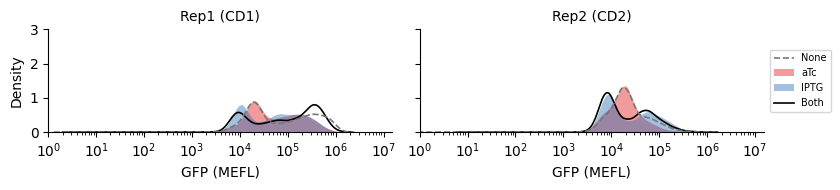

In [3]:
def plot_flow(group):
    """One row: the MEFL distribution per replicate, one line per inducer state."""
    # Positive events only, so a log axis can draw them
    mefl = {tag: {condition: flow.process_single_condition_file(
                      file_index[tag][(condition, group)], FSC_SSC, to_mefl[tag],
                      MEFL_CHANNELS, GFP_CHANNEL)[0]
                  for condition in CONDITIONS}
            for tag in FLOW_REPLICATES}

    figure, axes = plt.subplots(1, 2, figsize=(FLOW_WIDTH_IN, FLOW_HEIGHT_IN),
                                sharex=True, sharey=True)
    for ax, tag in zip(axes, FLOW_REPLICATES):
        flow.density_panel(ax, mefl[tag])
        ax.set_title(FLOW_LABELS[tag], fontsize=10)
        ax.set_xlabel("GFP (MEFL)")
        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)
    axes[0].set_ylabel("Density")
    axes[1].set_ylabel("")
    # Outside the axes, so the panels stay equal width
    axes[1].legend(fontsize=7, loc="center left", bbox_to_anchor=(1.02, 0.5),
                   borderaxespad=0)
    # No title; the file name carries the group
    figure.tight_layout()
    return figure


_ = plot_flow(f"circuit_{CIRCUIT}")
plt.show()


## All Circuits

In [4]:
import time

if not GENERATE_PNG:
    print("GENERATE_PNG is False: skipping the per-group PNGs")
else:
    png_dir = OUT_DIR / "analyse_flow"
    png_dir.mkdir(parents=True, exist_ok=True)
    started = time.perf_counter()
    for group in PAGES:
        # Chart PNGs are zero-padded; flow index keys are not
        stem = group if group == "pL2" else f"circuit_{int(group.split('_')[1]):02d}"
        figure = plot_flow(group)
        # No bbox_inches: sbol.composite needs equal widths
        figure.savefig(png_dir / f"{stem}.png", dpi=PNG_DPI)
        plt.close(figure)
    print(f"{png_dir}: {len(PAGES)} PNGs, {time.perf_counter() - started:.0f} s")


out/analyse_flow: 93 PNGs, 1126 s
